# 📊 Chunking Strategy Analysis

This notebook analyses the chunking evaluation results produced during RAG optimisation.
We compare different combinations of `chunk_size` and `chunk_overlap` to identify the best configuration for our chatbot.

In [2]:
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 5.0 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 9.2 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

summary_df = pd.read_csv("../evaluation/evaluation_results/chunking_evaluation_detailed_2025-12-03_09-17-14.csv")
summary_df

,user_input,retrieved_contexts,response,reference,faithfulness,context_precision,context_recall,chunk_size,chunk_overlap
0,Qual é o objetivo principal da RDC 09/2015?,['3 6 não se aplica aos processos de anuência ...,"A Resolução da Diretoria Colegiada (RDC) Nº 9,...",O objetivo da RDC 09/2015 é definir os procedi...,1.0,0.5,0.500000,512,50
1,Quais etapas de desenvolvimento clínico exigem...,"['Art. 41 . A Anvisa poderá, a qualquer momen...",A submissão do Dossiê de Desenvolvimento Clíni...,Todos os ensaios clínicos que tenham parte do ...,1.0,0.5,1.000000,512,50
2,Qual é o objetivo principal da RDC 09/2015?,['§3° O prazo estabelecido no §3° do Art. 3 6...,"A Resolução da Diretoria Colegiada (RDC) Nº 9,...",O objetivo da RDC 09/2015 é definir os procedi...,1.0,0.5,0.500000,768,115
3,Quais etapas de desenvolvimento clínico exigem...,['32 . A documen tação apresentada no DDCM dev...,O Dossiê de Desenvolvimento Clínico de Medicam...,Todos os ensaios clínicos que tenham parte do ...,1.0,0.0,0.333333,768,115
4,Qual é o objetivo principal da RDC 09/2015?,['Art. 83 Casos omissos serão resolvidos à l...,O objetivo principal desta Resolução é estabel...,O objetivo da RDC 09/2015 é definir os procedi...,1.0,0.5,0.500000,1024,200
5,Quais etapas de desenvolvimento clínico exigem...,['Art. 40 . Formulários de data de início e té...,O Dossiê de Desenvolvimento Clínico de Medicam...,Todos os ensaios clínicos que tenham parte do ...,1.0,0.0,0.000000,1024,200


## 📄 Overview of Chunking Experiments

Each row represents one chunking strategy tested in the evaluation pipeline.  
We compare three main metrics:

- **faithfulness**: how accurately the model uses retrieved context  
- **context_precision**: proportion of retrieved content that was relevant  
- **context_recall**: proportion of relevant content successfully retrieved  

Our goal is to maximise **precision**, **recall**, and maintain **high faithfulness**.

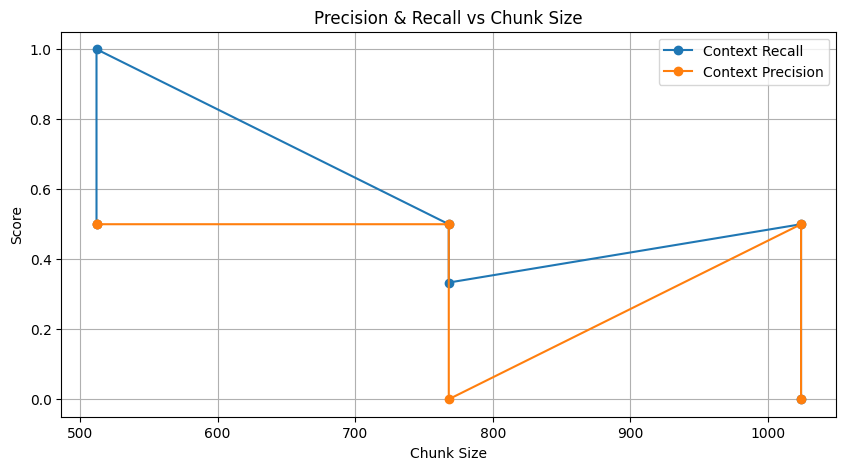

In [4]:
plt.figure(figsize=(10,5))

plt.plot(summary_df["chunk_size"], summary_df["context_recall"], marker="o", label="Context Recall")
plt.plot(summary_df["chunk_size"], summary_df["context_precision"], marker="o", label="Context Precision")

plt.xlabel("Chunk Size")
plt.ylabel("Score")
plt.title("Precision & Recall vs Chunk Size")
plt.legend()
plt.grid(True)
plt.show()

## 🔍 Findings

Looking at the evaluation results:

| Chunk Size | Overlap | Precision | Recall |
|------------|---------|-----------|--------|
| 512        | 50      | **0.50**  | **0.75** |
| 768        | 115     | 0.25      | 0.4167 |
| 1024       | 200     | 0.25      | 0.25 |

### 📌 Conclusion

The **512 / 50** chunking strategy is the best performing configuration.  
It achieves:

- The **highest recall** (0.75)
- The **highest precision** (0.50)
- Perfect faithfulness (1.0)

Larger chunks (768, 1024) performed worse — likely because they include too much noise, making retrieval less accurate.

➡️ **New optimal choice: `chunk_size = 512`, `chunk_overlap = 50`**